<a href="https://colab.research.google.com/github/Nandishsk-07/CodeAlpha_HandwrittenCharacterRecognition/blob/main/CodeAlpha_HandwrittenCharacterRecognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Setup**

In [ ]:
!pip install -q tensorflow_datasets

In [ ]:
import os, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style("whitegrid")
print("TensorFlow:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---------------- Configuration ----------------
BATCH_SIZE = 128
VAL_SPLIT = 0.1            # share of the training data used for validation
EPOCHS_MLP = 8
EPOCHS_MNIST = 12
EPOCHS_CNN = 30            # upper limit; EarlyStopping usually stops earlier
TRANSPOSE_EMNIST = True    # EMNIST images are stored rotated/mirrored; see the check in Part B

# EMNIST Balanced class names (47): digits, upper-case letters, and 11 lower-case letters
EMNIST_LABELS = list("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt")
MNIST_LABELS = [str(i) for i in range(10)]
assert len(EMNIST_LABELS) == 47

**2. Helper Functions**

In [ ]:
def load_mnist():
    (x_tr, y_tr), (x_te, y_te) = tf.keras.datasets.mnist.load_data()
    return x_tr[..., None], y_tr, x_te[..., None], y_te

def load_emnist_balanced():
    """Download EMNIST Balanced through tensorflow_datasets (about 0.5 GB, takes a few minutes the first time)."""
    import tensorflow_datasets as tfds
    tr_x, tr_y = tfds.as_numpy(tfds.load("emnist/balanced", split="train", batch_size=-1, as_supervised=True))
    te_x, te_y = tfds.as_numpy(tfds.load("emnist/balanced", split="test", batch_size=-1, as_supervised=True))
    return tr_x, tr_y, te_x, te_y

# --- loaders defined above ---

def show_grid(X, y, names, n=16, rows=2, title=None, seed=SEED):
    idx = np.random.default_rng(seed).choice(len(X), size=n, replace=False)
    cols = n // rows
    fig, axes = plt.subplots(rows, cols, figsize=(1.5 * cols, 1.7 * rows))
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(X[i].squeeze(), cmap="gray"); ax.set_title(names[y[i]], fontsize=11); ax.axis("off")
    if title: plt.suptitle(title)
    plt.tight_layout(); plt.show()

def plot_class_counts(y, names, title):
    counts = pd.Series(y).value_counts().sort_index()
    plt.figure(figsize=(max(7, len(names) * 0.3), 3.5))
    plt.bar([names[i] for i in counts.index], counts.values)
    plt.title(title); plt.ylabel("Images"); plt.tight_layout(); plt.show()

def plot_history(h, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].plot(h.history["accuracy"], label="train"); axes[0].plot(h.history["val_accuracy"], label="validation")
    axes[0].set_title(f"{title} - accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
    axes[1].plot(h.history["loss"], label="train"); axes[1].plot(h.history["val_loss"], label="validation")
    axes[1].set_title(f"{title} - loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

def make_callbacks():
    return [callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]

def build_mlp(n_classes, name="MLP"):
    m = models.Sequential([
        layers.Input(shape=(28, 28, 1)), layers.Flatten(),
        layers.Dense(256, activation="relu"), layers.Dropout(0.3),
        layers.Dense(128, activation="relu"),
        layers.Dense(n_classes, activation="softmax")], name=name)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def build_cnn(n_classes, augment=False, name="CNN"):
    # Augmentation layers are only active during training. No flips: they would turn b into d, etc.
    aug = []
    if augment:
        aug = [layers.RandomRotation(0.03, fill_mode="constant", fill_value=0.0),       # about +-10 degrees
               layers.RandomZoom(0.1, fill_mode="constant", fill_value=0.0),
               layers.RandomTranslation(0.1, 0.1, fill_mode="constant", fill_value=0.0)]
    m = models.Sequential([layers.Input(shape=(28, 28, 1))] + aug + [
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(32, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.Conv2D(64, 3, padding="same"), layers.BatchNormalization(), layers.Activation("relu"),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(256, activation="relu"), layers.Dropout(0.5),
        layers.Dense(n_classes, activation="softmax")], name=name)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def evaluate_model(model, X, y):
    probs = model.predict(X, batch_size=512, verbose=0)
    pred = probs.argmax(axis=1)
    return probs, pred, accuracy_score(y, pred), f1_score(y, pred, average="macro")

def top_confusions(cm, names, k=10):
    cm2 = cm.copy(); np.fill_diagonal(cm2, 0)
    flat = np.argsort(cm2.ravel())[::-1][:k]
    rows = [(names[i], names[j], int(cm2[i, j])) for i, j in zip(*np.unravel_index(flat, cm2.shape))]
    return pd.DataFrame(rows, columns=["True character", "Predicted as", "Times"])

def show_errors(X, y_true, probs, names, n=16):
    pred = probs.argmax(axis=1)
    wrong = np.where(pred != y_true)[0]
    if len(wrong) == 0:
        print("No misclassified images."); return
    sel = np.random.default_rng(SEED).choice(wrong, size=min(n, len(wrong)), replace=False)
    rows = 2; cols = int(np.ceil(len(sel) / rows))
    fig, axes = plt.subplots(rows, cols, figsize=(1.7 * cols, 2.2 * rows))
    for ax in np.ravel(axes): ax.axis("off")
    for ax, i in zip(np.ravel(axes), sel):
        ax.imshow(X[i].squeeze(), cmap="gray")
        ax.set_title(f"true: {names[y_true[i]]}\npred: {names[pred[i]]} ({probs[i].max():.0%})", fontsize=9, color="crimson")
    plt.suptitle("Misclassified examples"); plt.tight_layout(); plt.show()

results = []   # collects (dataset, model, accuracy, macro F1)

**Part A - MNIST(digits)**

**A1. Load and Explore**

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: (60000, 28, 28, 1) | Test: (10000, 28, 28, 1)
Pixel range: 0 - 255 | dtype: uint8


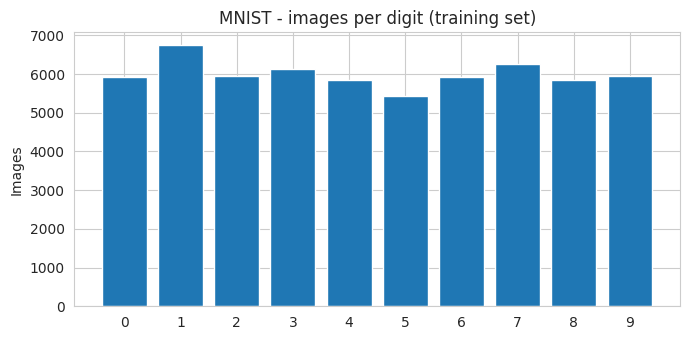

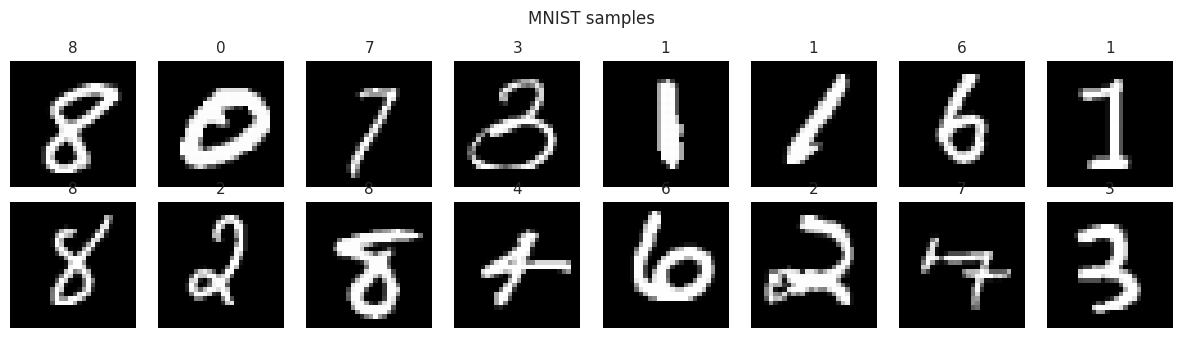

In [ ]:
Xm_train_full, ym_train_full, Xm_test, ym_test = load_mnist()
print("Train:", Xm_train_full.shape, "| Test:", Xm_test.shape)
print("Pixel range:", Xm_train_full.min(), "-", Xm_train_full.max(), "| dtype:", Xm_train_full.dtype)
plot_class_counts(ym_train_full, MNIST_LABELS, "MNIST - images per digit (training set)")
show_grid(Xm_train_full, ym_train_full, MNIST_LABELS, title="MNIST samples")

**A2. Preprocess**

In [ ]:
Xm_train_full = Xm_train_full.astype("float32") / 255.0
Xm_test = Xm_test.astype("float32") / 255.0

Xm_train, Xm_val, ym_train, ym_val = train_test_split(
    Xm_train_full, ym_train_full, test_size=VAL_SPLIT, stratify=ym_train_full, random_state=SEED)
print("Train:", Xm_train.shape, "| Val:", Xm_val.shape, "| Test:", Xm_test.shape)

Train: (54000, 28, 28, 1) | Val: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)


**A3. Baseline MLP vs CNN**

In [ ]:
mlp_m = build_mlp(10, name="MNIST_MLP")
h_mlp_m = mlp_m.fit(Xm_train, ym_train, validation_data=(Xm_val, ym_val), epochs=EPOCHS_MLP,
                    batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=2)

Epoch 1/8
422/422 - 8s - 19ms/step - accuracy: 0.8975 - loss: 0.3423 - val_accuracy: 0.9523 - val_loss: 0.1605 - learning_rate: 0.0010
Epoch 2/8
422/422 - 2s - 6ms/step - accuracy: 0.9569 - loss: 0.1435 - val_accuracy: 0.9667 - val_loss: 0.1137 - learning_rate: 0.0010
Epoch 3/8
422/422 - 3s - 6ms/step - accuracy: 0.9681 - loss: 0.1043 - val_accuracy: 0.9740 - val_loss: 0.0929 - learning_rate: 0.0010
Epoch 4/8
422/422 - 5s - 12ms/step - accuracy: 0.9733 - loss: 0.0846 - val_accuracy: 0.9745 - val_loss: 0.0911 - learning_rate: 0.0010
Epoch 5/8
422/422 - 3s - 6ms/step - accuracy: 0.9770 - loss: 0.0705 - val_accuracy: 0.9762 - val_loss: 0.0860 - learning_rate: 0.0010
Epoch 6/8
422/422 - 2s - 6ms/step - accuracy: 0.9814 - loss: 0.0592 - val_accuracy: 0.9787 - val_loss: 0.0777 - learning_rate: 0.0010
Epoch 7/8
422/422 - 2s - 5ms/step - accuracy: 0.9823 - loss: 0.0535 - val_accuracy: 0.9773 - val_loss: 0.0783 - learning_rate: 0.0010
Epoch 8/8
422/422 - 2s - 4ms/step - accuracy: 0.9843 - loss:

In [ ]:
cnn_m = build_cnn(10, augment=True, name="MNIST_CNN")
cnn_m.summary()
h_cnn_m = cnn_m.fit(Xm_train, ym_train, validation_data=(Xm_val, ym_val), epochs=EPOCHS_MNIST,
                    batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=2)

Model: "MNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             

 Total params: 871,402 (3.32 MB)

 Trainable params: 871,018 (3.32 MB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/12
422/422 - 22s - 53ms/step - accuracy: 0.7549 - loss: 0.7548 - val_accuracy: 0.1003 - val_loss: 6.9583 - learning_rate: 0.0010
Epoch 2/12
422/422 - 9s - 22ms/step - accuracy: 0.9215 - loss: 0.2562 - val_accuracy: 0.9808 - val_loss: 0.0612 - learning_rate: 0.0010
Epoch 3/12
422/422 - 9s - 22ms/step - accuracy: 0.9429 - loss: 0.1933 - val_accuracy: 0.9813 - val_loss: 0.0663 - learning_rate: 0.0010
Epoch 4/12
422/422 - 9s - 22ms/step - accuracy: 0.9524 - loss: 0.1630 - val_accuracy: 0.9847 - val_loss: 0.0490 - learning_rate: 0.0010
Epoch 5/12
422/422 - 10s - 23ms/step - accuracy: 0.9603 - loss: 0.1360 - val_accuracy: 0.9800 - val_loss: 0.0732 - learning_rate: 0.0010
Epoch 6/12
422/422 - 9s - 22ms/step - accuracy: 0.9649 - loss: 0.1199 - val_accuracy: 0.9728 - val_loss: 0.1105 - learning_rate: 0.0010
Epoch 7/12
422/422 - 9s - 22ms/step - accuracy: 0.9736 - loss: 0.0904 - val_accuracy: 0.9848 - val_loss: 0.0592 - learning_rate: 5.0000e-04
Epoch 8/12
422/422 - 10s - 24ms/step - acc

**A4. Evaluate on the MNIST Test Set**

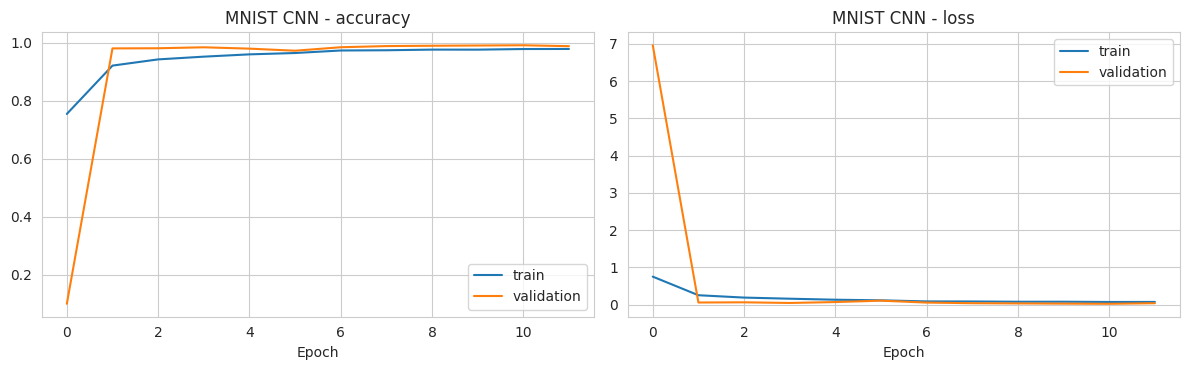

  Dataset           Model  Accuracy  Macro F1
0   MNIST  MLP (baseline)    0.9794    0.9793
1   MNIST             CNN    0.9951    0.9951
2   MNIST  MLP (baseline)    0.9794    0.9793
3   MNIST             CNN    0.9951    0.9951

CNN classification report
              precision    recall  f1-score   support

           0     0.9959    0.9969    0.9964       980
           1     0.9956    0.9956    0.9956      1135
           2     0.9971    0.9971    0.9971      1032
           3     0.9970    0.9950    0.9960      1010
           4     0.9949    0.9969    0.9959       982
           5     0.9889    0.9966    0.9927       892
           6     0.9969    0.9916    0.9942       958
           7     0.9894    0.9981    0.9937      1028
           8     0.9979    0.9918    0.9949       974
           9     0.9970    0.9911    0.9940      1009

    accuracy                         0.9951     10000
   macro avg     0.9951    0.9951    0.9951     10000
weighted avg     0.9951    0.9951    0.

In [ ]:
plot_history(h_cnn_m, "MNIST CNN")

probs_mlp_m, pred_mlp_m, acc, f1 = evaluate_model(mlp_m, Xm_test, ym_test)
results.append(("MNIST", "MLP (baseline)", acc, f1))
probs_cnn_m, pred_cnn_m, acc, f1 = evaluate_model(cnn_m, Xm_test, ym_test)
results.append(("MNIST", "CNN", acc, f1))
print(pd.DataFrame(results, columns=["Dataset", "Model", "Accuracy", "Macro F1"]).round(4))

print("\nCNN classification report")
print(classification_report(ym_test, pred_cnn_m, target_names=MNIST_LABELS, digits=4))

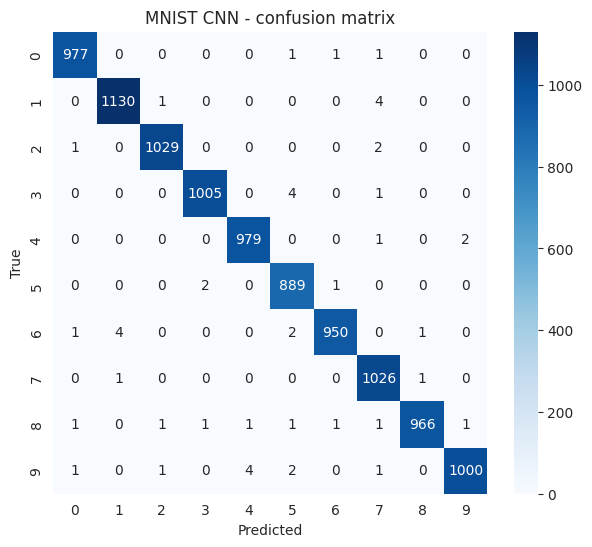

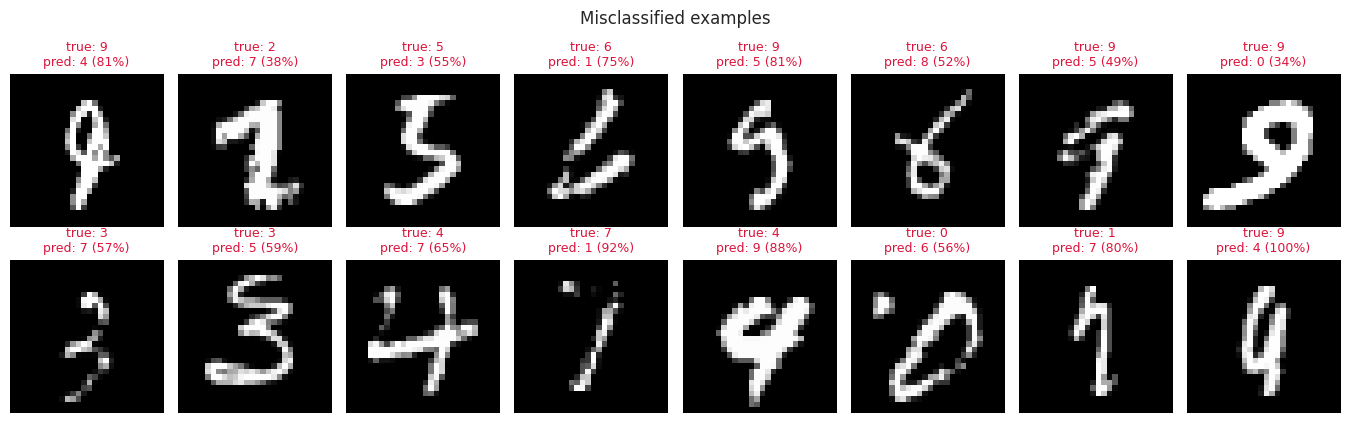

In [ ]:
cm = confusion_matrix(ym_test, pred_cnn_m)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=MNIST_LABELS, yticklabels=MNIST_LABELS)
plt.title("MNIST CNN - confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()
show_errors(Xm_test, ym_test, probs_cnn_m, MNIST_LABELS)

**Part B - EMNIST Balanced (digits + letters)**

**B1. Load the data**

In [ ]:
!pip install -q importlib_resources

In [ ]:
Xe_train_full, ye_train_full, Xe_test, ye_test = load_emnist_balanced()
print("Train:", Xe_train_full.shape, "| Test:", Xe_test.shape, "| Classes:", len(np.unique(ye_train_full)))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/balanced/incomplete.BISFX6_3.1.0/emnist-train.tfrecord-[0-9][0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/balanced/incomplete.BISFX6_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/balanced/3.1.0. Subsequent calls will reuse this data.
Train: (112800, 28, 28, 1) | Test: (18800, 28, 28, 1) | Classes: 47


**B2. Orientation Check**

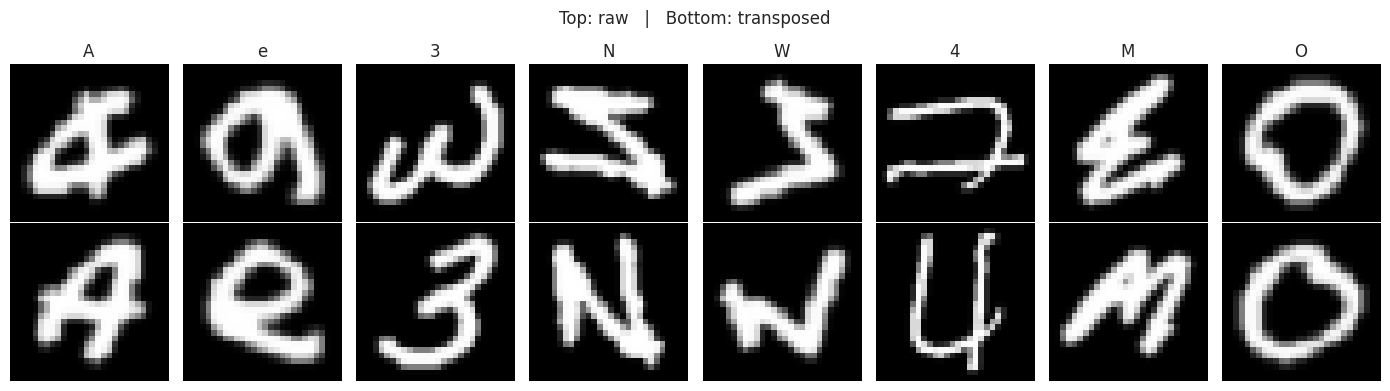

In [ ]:
idx = np.random.default_rng(1).choice(len(Xe_train_full), size=8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for k, i in enumerate(idx):
    axes[0, k].imshow(Xe_train_full[i].squeeze(), cmap="gray"); axes[0, k].set_title(EMNIST_LABELS[ye_train_full[i]]); axes[0, k].axis("off")
    axes[1, k].imshow(np.transpose(Xe_train_full[i].squeeze()), cmap="gray"); axes[1, k].axis("off")
axes[0, 0].set_ylabel("raw"); plt.suptitle("Top: raw   |   Bottom: transposed")
plt.tight_layout(); plt.show()

In [ ]:
if TRANSPOSE_EMNIST:
    Xe_train_full = np.transpose(Xe_train_full, (0, 2, 1, 3))
    Xe_test = np.transpose(Xe_test, (0, 2, 1, 3))
print("Orientation fixed:", TRANSPOSE_EMNIST)

Orientation fixed: True


**B3.Explore**

Pixel range: 0 - 255 | dtype: uint8


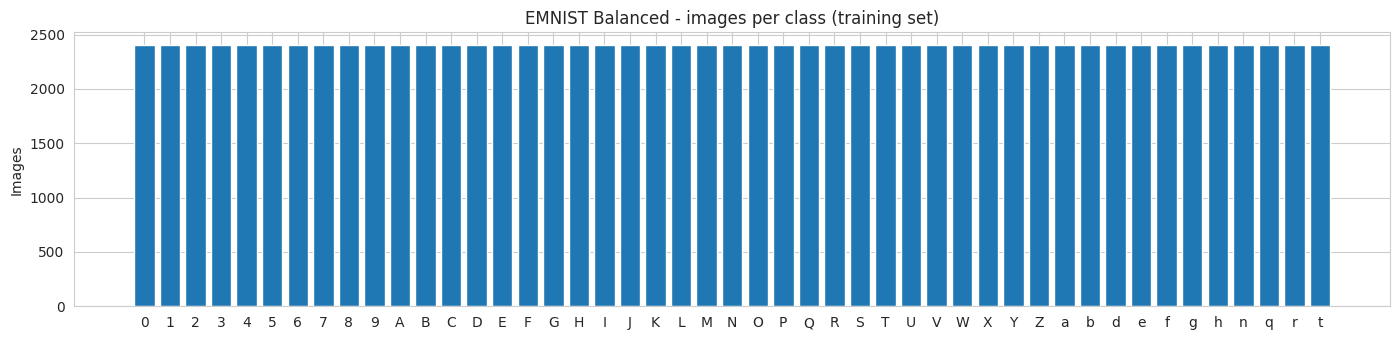

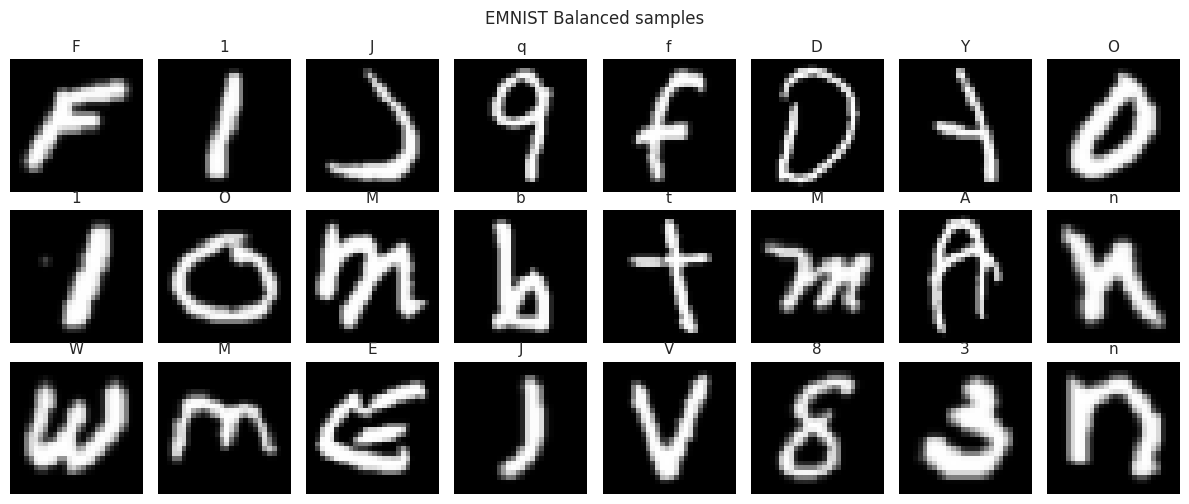

In [ ]:
print("Pixel range:", Xe_train_full.min(), "-", Xe_train_full.max(), "| dtype:", Xe_train_full.dtype)
plot_class_counts(ye_train_full, EMNIST_LABELS, "EMNIST Balanced - images per class (training set)")
show_grid(Xe_train_full, ye_train_full, EMNIST_LABELS, n=24, rows=3, title="EMNIST Balanced samples")

**B4. Preprocess and Split**

In [ ]:
Xe_train_full = Xe_train_full.astype("float32") / 255.0
Xe_test = Xe_test.astype("float32") / 255.0

Xe_train, Xe_val, ye_train, ye_val = train_test_split(
    Xe_train_full, ye_train_full, test_size=VAL_SPLIT, stratify=ye_train_full, random_state=SEED)
print("Train:", Xe_train.shape, "| Val:", Xe_val.shape, "| Test:", Xe_test.shape)

Train: (101520, 28, 28, 1) | Val: (11280, 28, 28, 1) | Test: (18800, 28, 28, 1)


**B5. Data Augmentation**

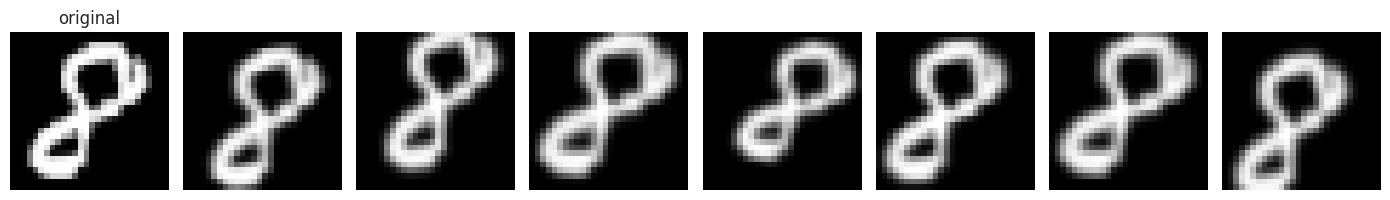

In [ ]:
preview = tf.keras.Sequential([
    layers.RandomRotation(0.03, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom(0.1, fill_mode="constant", fill_value=0.0),
    layers.RandomTranslation(0.1, 0.1, fill_mode="constant", fill_value=0.0)])
sample = Xe_train[:1]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
axes[0].imshow(sample[0].squeeze(), cmap="gray"); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(preview(sample, training=True)[0].numpy().squeeze(), cmap="gray"); ax.axis("off")
plt.tight_layout(); plt.show()

**B6. Baseline MLP**

In [ ]:
mlp_e = build_mlp(47, name="EMNIST_MLP")
h_mlp_e = mlp_e.fit(Xe_train, ye_train, validation_data=(Xe_val, ye_val), epochs=EPOCHS_MLP,
                    batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=2)

Epoch 1/8
794/794 - 12s - 15ms/step - accuracy: 0.6296 - loss: 1.2830 - val_accuracy: 0.7668 - val_loss: 0.7564 - learning_rate: 0.0010
Epoch 2/8
794/794 - 2s - 3ms/step - accuracy: 0.7582 - loss: 0.7749 - val_accuracy: 0.7966 - val_loss: 0.6211 - learning_rate: 0.0010
Epoch 3/8
794/794 - 2s - 3ms/step - accuracy: 0.7848 - loss: 0.6696 - val_accuracy: 0.8133 - val_loss: 0.5630 - learning_rate: 0.0010
Epoch 4/8
794/794 - 3s - 4ms/step - accuracy: 0.8007 - loss: 0.6088 - val_accuracy: 0.8236 - val_loss: 0.5313 - learning_rate: 0.0010
Epoch 5/8
794/794 - 2s - 3ms/step - accuracy: 0.8089 - loss: 0.5757 - val_accuracy: 0.8293 - val_loss: 0.5192 - learning_rate: 0.0010
Epoch 6/8
794/794 - 2s - 3ms/step - accuracy: 0.8169 - loss: 0.5475 - val_accuracy: 0.8299 - val_loss: 0.5061 - learning_rate: 0.0010
Epoch 7/8
794/794 - 3s - 3ms/step - accuracy: 0.8227 - loss: 0.5224 - val_accuracy: 0.8336 - val_loss: 0.4860 - learning_rate: 0.0010
Epoch 8/8
794/794 - 2s - 3ms/step - accuracy: 0.8270 - loss:

**B7 CNN with Augmentation**

In [ ]:
cnn_e = build_cnn(47, augment=True, name="EMNIST_CNN")
cnn_e.summary()
h_cnn_e = cnn_e.fit(Xe_train, ye_train, validation_data=(Xe_val, ye_val), epochs=EPOCHS_CNN,
                    batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=2)

Model: "EMNIST_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_2               │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             

 Total params: 880,911 (3.36 MB)

 Trainable params: 880,527 (3.36 MB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/30
794/794 - 22s - 27ms/step - accuracy: 0.2997 - loss: 2.4105 - val_accuracy: 0.7739 - val_loss: 0.7430 - learning_rate: 0.0010
Epoch 2/30
794/794 - 18s - 23ms/step - accuracy: 0.5109 - loss: 1.5055 - val_accuracy: 0.8024 - val_loss: 0.6009 - learning_rate: 0.0010
Epoch 3/30
794/794 - 17s - 22ms/step - accuracy: 0.5794 - loss: 1.2694 - val_accuracy: 0.8091 - val_loss: 0.5387 - learning_rate: 0.0010
Epoch 4/30
794/794 - 18s - 22ms/step - accuracy: 0.6266 - loss: 1.1281 - val_accuracy: 0.8117 - val_loss: 0.5482 - learning_rate: 0.0010
Epoch 5/30
794/794 - 17s - 22ms/step - accuracy: 0.6593 - loss: 1.0246 - val_accuracy: 0.8145 - val_loss: 0.5289 - learning_rate: 0.0010
Epoch 6/30
794/794 - 17s - 22ms/step - accuracy: 0.6833 - loss: 0.9498 - val_accuracy: 0.8488 - val_loss: 0.4297 - learning_rate: 0.0010
Epoch 7/30
794/794 - 21s - 26ms/step - accuracy: 0.7169 - loss: 0.8512 - val_accuracy: 0.8528 - val_loss: 0.4194 - learning_rate: 0.0010
Epoch 8/30
794/794 - 18s - 22ms/step - ac

**B8. Training curves**

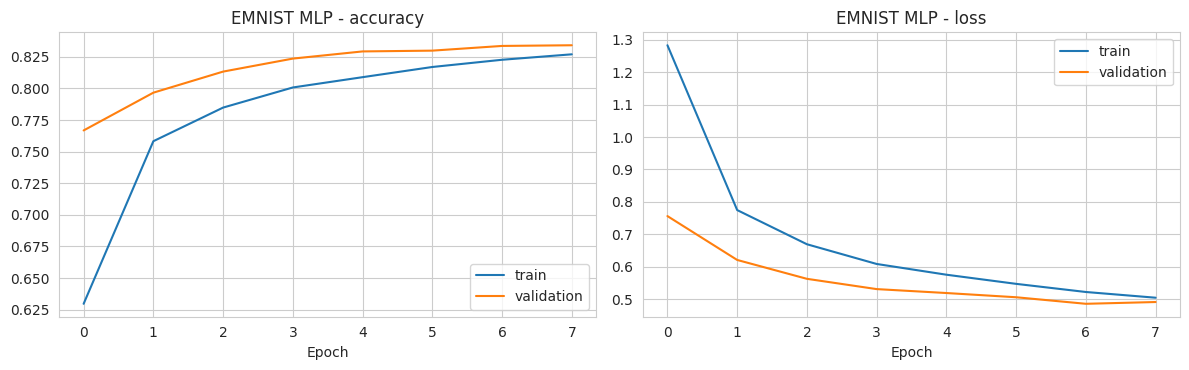

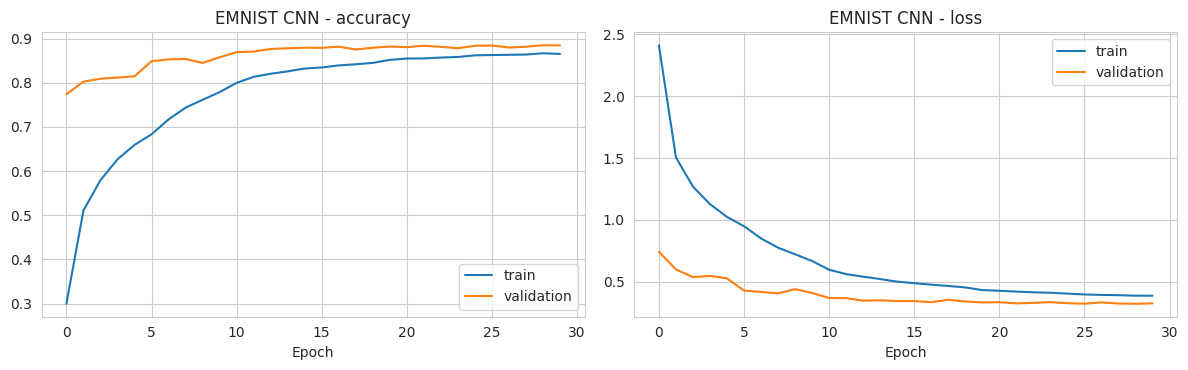

In [ ]:
plot_history(h_mlp_e, "EMNIST MLP")
plot_history(h_cnn_e, "EMNIST CNN")

**B9. Evaluate on the EMNIST test set**

In [ ]:
probs_mlp_e, pred_mlp_e, acc, f1 = evaluate_model(mlp_e, Xe_test, ye_test)
results.append(("EMNIST Balanced", "MLP (baseline)", acc, f1))
probs_cnn_e, pred_cnn_e, acc, f1 = evaluate_model(cnn_e, Xe_test, ye_test)
results.append(("EMNIST Balanced", "CNN", acc, f1))

results_df = pd.DataFrame(results, columns=["Dataset", "Model", "Accuracy", "Macro F1"]).round(4)
print("Random-guess accuracy would be %.3f (47 classes)\n" % (1 / 47))
results_df

Random-guess accuracy would be 0.021 (47 classes)



,Dataset,Model,Accuracy,Macro F1
0,MNIST,MLP (baseline),0.9794,0.9793
1,MNIST,CNN,0.9951,0.9951
2,MNIST,MLP (baseline),0.9794,0.9793
3,MNIST,CNN,0.9951,0.9951
4,EMNIST Balanced,MLP (baseline),0.8385,0.8372
5,EMNIST Balanced,CNN,0.8829,0.8809


In [ ]:
print(classification_report(ye_test, pred_cnn_e, labels=list(range(47)), target_names=EMNIST_LABELS, digits=3))

              precision    recall  f1-score   support

           0      0.589     0.858     0.699       400
           1      0.486     0.713     0.578       400
           2      0.934     0.855     0.893       400
           3      0.993     0.993     0.993       400
           4      0.936     0.955     0.946       400
           5      0.909     0.953     0.930       400
           6      0.942     0.930     0.936       400
           7      0.978     0.983     0.980       400
           8      0.967     0.958     0.962       400
           9      0.657     0.815     0.728       400
           A      0.956     0.988     0.972       400
           B      0.938     0.985     0.961       400
           C      0.984     0.932     0.958       400
           D      0.915     0.945     0.930       400
           E      0.973     0.980     0.976       400
           F      0.728     0.515     0.603       400
           G      0.892     0.973     0.931       400
           H      0.957    

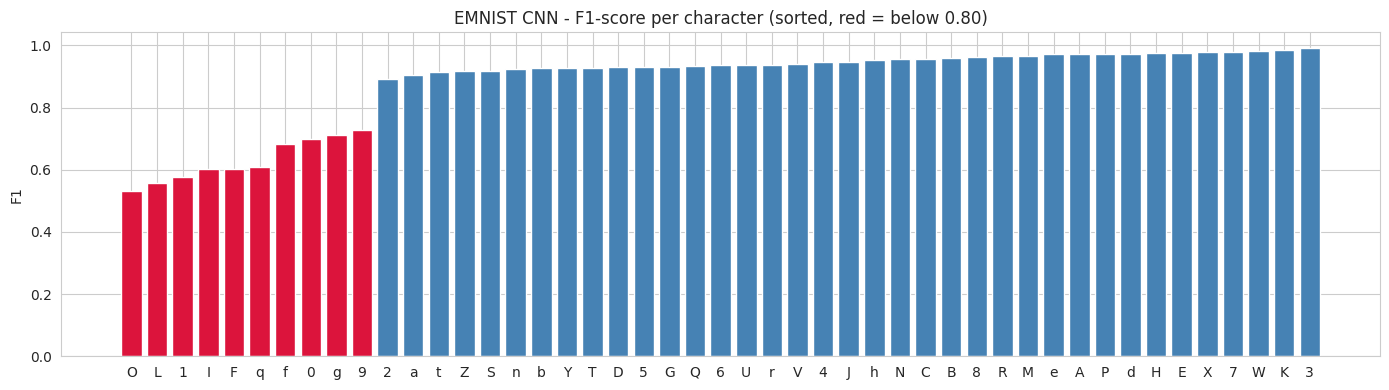

In [ ]:
# Per-class F1: which characters are easy and which are hard?
from sklearn.metrics import precision_recall_fscore_support
_, _, f1_cls, _ = precision_recall_fscore_support(ye_test, pred_cnn_e, labels=list(range(47)), zero_division=0)
order = np.argsort(f1_cls)
plt.figure(figsize=(14, 4))
plt.bar([EMNIST_LABELS[i] for i in order], f1_cls[order], color=["crimson" if v < 0.8 else "steelblue" for v in f1_cls[order]])
plt.title("EMNIST CNN - F1-score per character (sorted, red = below 0.80)"); plt.ylabel("F1"); plt.tight_layout(); plt.show()

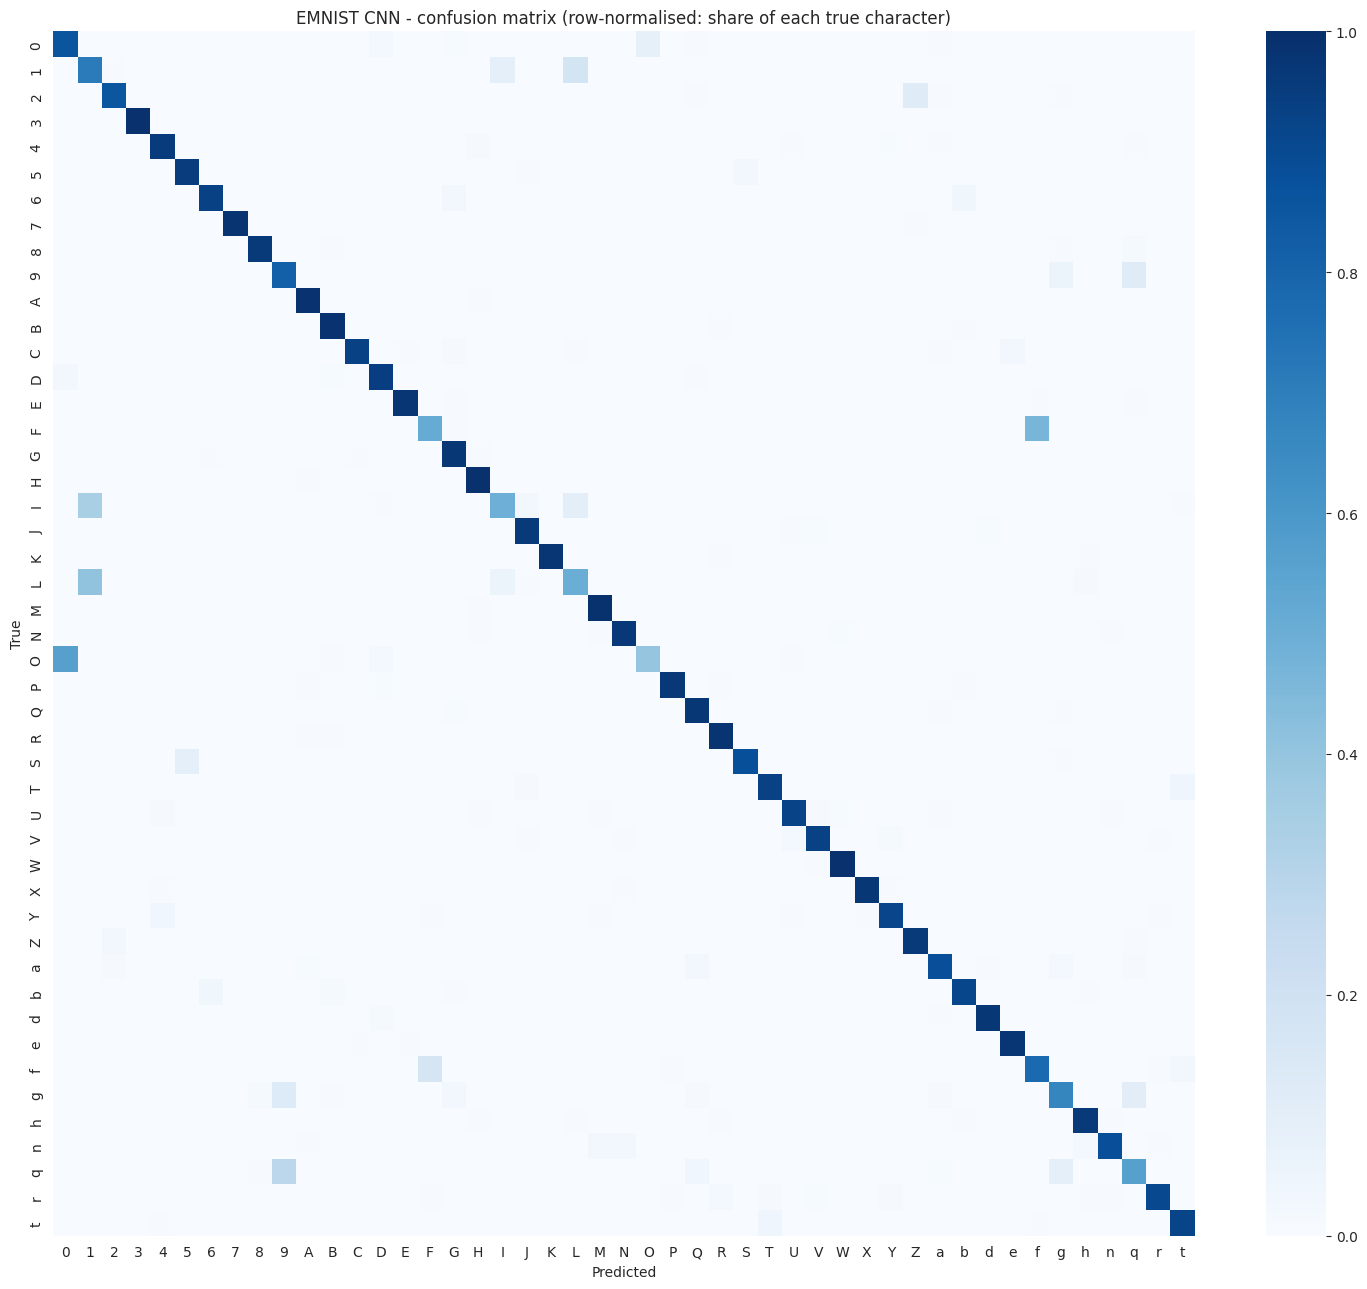

In [ ]:
cm_e = confusion_matrix(ye_test, pred_cnn_e, labels=list(range(47)))
cm_norm = cm_e / cm_e.sum(axis=1, keepdims=True)
plt.figure(figsize=(15, 13))
sns.heatmap(cm_norm, cmap="Blues", xticklabels=EMNIST_LABELS, yticklabels=EMNIST_LABELS, vmin=0, vmax=1)
plt.title("EMNIST CNN - confusion matrix (row-normalised: share of each true character)")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.tight_layout(); plt.show()

In [ ]:
print("Most confused character pairs:")
top_confusions(cm_e, EMNIST_LABELS, k=12)

Most confused character pairs:


,True character,Predicted as,Times
0,O,0,224
1,F,f,188
2,L,1,163
3,I,1,137
4,q,9,114
5,1,L,72
6,f,F,69
7,g,9,53
8,9,q,49
9,2,Z,48


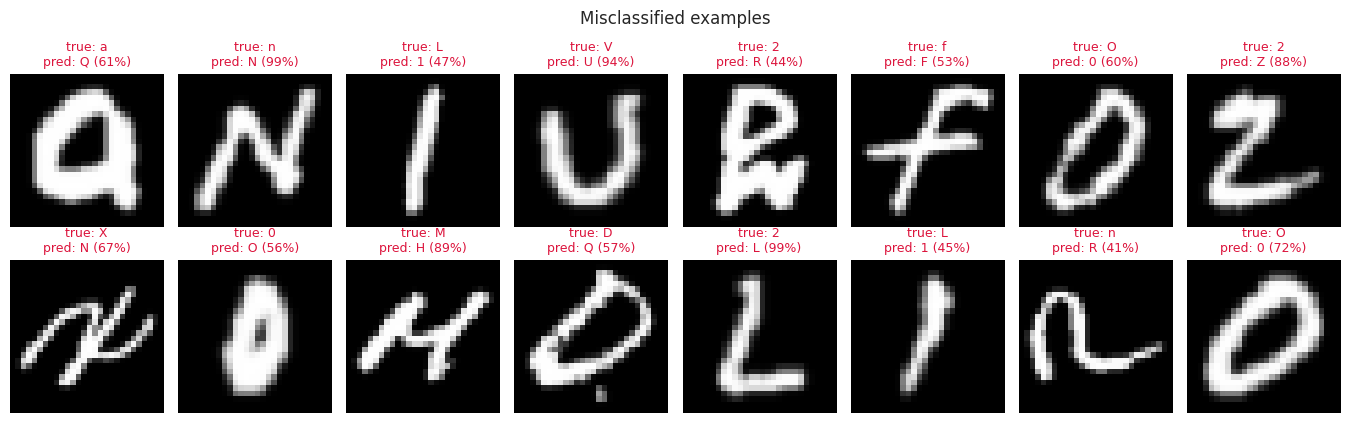

In [ ]:
show_errors(Xe_test, ye_test, probs_cnn_e, EMNIST_LABELS)

**c1. Results Summery**

,Dataset,Model,Accuracy,Macro F1
0,MNIST,MLP (baseline),0.9794,0.9793
1,MNIST,CNN,0.9951,0.9951
2,MNIST,MLP (baseline),0.9794,0.9793
3,MNIST,CNN,0.9951,0.9951
4,EMNIST Balanced,MLP (baseline),0.8385,0.8372
5,EMNIST Balanced,CNN,0.8829,0.8809


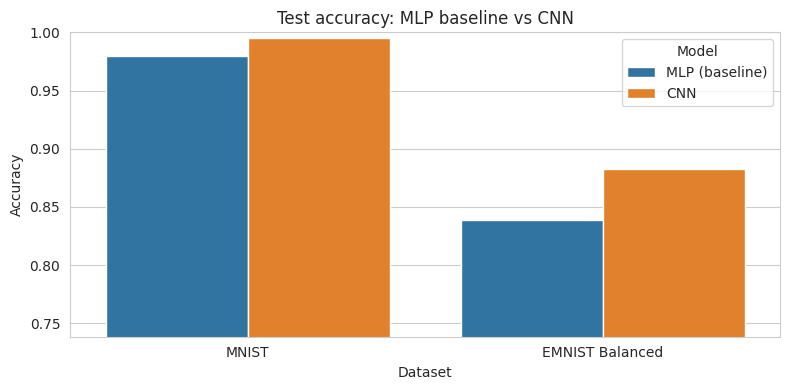

In [ ]:
summary = pd.DataFrame(results, columns=["Dataset", "Model", "Accuracy", "Macro F1"]).round(4)
display(summary)
plt.figure(figsize=(8, 4))
sns.barplot(data=summary, x="Dataset", y="Accuracy", hue="Model")
plt.ylim(max(0, summary["Accuracy"].min() - 0.1), 1.0); plt.title("Test accuracy: MLP baseline vs CNN")
plt.tight_layout(); plt.show()

**c2. Predict a character from any image**

In [ ]:
def preprocess_image(img):
    """Accepts a file path, PIL image, numpy array or Gradio sketch dict. Returns (1, 28, 28, 1) float array or None."""
    if isinstance(img, dict):                      # Gradio sketchpad returns a dict
        img = img.get("composite")
    if img is None:
        return None
    if isinstance(img, str):
        img = Image.open(img)
    elif isinstance(img, np.ndarray):
        img = Image.fromarray(img.astype("uint8"))
    if img.mode in ("RGBA", "LA", "P"):            # put transparent drawings on a white background
        rgba = img.convert("RGBA")
        bg = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
        bg.alpha_composite(rgba)
        img = bg
    a = np.array(img.convert("L")).astype("float32")
    if a.mean() > 127:                              # dark ink on light paper -> white strokes on black
        a = 255.0 - a
    if a.max() <= 0:
        return None
    a = a / a.max() * 255.0
    ys, xs = np.where(a > 0.2 * 255.0)              # bounding box of the strokes
    if len(ys) == 0:
        return None
    a = a[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = a.shape
    side = max(h, w); pad = max(1, int(0.25 * side))
    canvas = np.zeros((side + 2 * pad, side + 2 * pad), dtype="float32")
    top = pad + (side - h) // 2; left = pad + (side - w) // 2
    canvas[top:top + h, left:left + w] = a
    small = Image.fromarray(canvas.astype("uint8")).resize((28, 28), Image.LANCZOS)
    return (np.array(small, dtype="float32") / 255.0)[None, ..., None]

def predict_character(img, model=None, names=None, top=3, show=True):
    model = model or cnn_e
    names = names or EMNIST_LABELS
    x = preprocess_image(img)
    if x is None:
        print("No character found in the image."); return None
    probs = model.predict(x, verbose=0)[0]
    best = np.argsort(probs)[::-1][:top]
    print("Top predictions:", ",  ".join(f"{names[i]} ({probs[i]:.1%})" for i in best))
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(7, 2.8))
        axes[0].imshow(x[0].squeeze(), cmap="gray"); axes[0].set_title("what the model sees"); axes[0].axis("off")
        axes[1].barh([names[i] for i in best][::-1], probs[best][::-1]); axes[1].set_xlim(0, 1); axes[1].set_title("confidence")
        plt.tight_layout(); plt.show()
    return {names[i]: float(probs[i]) for i in best}


True character: 9
Top predictions: 9 (79.6%),  q (16.6%),  g (3.8%)


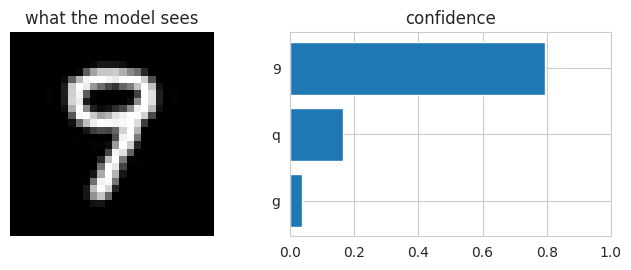

True character: t
Top predictions: t (98.6%),  T (1.2%),  f (0.1%)


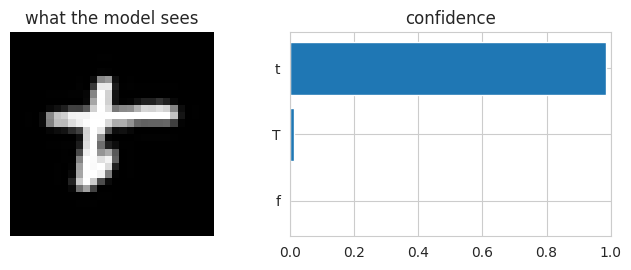

True character: T
Top predictions: T (98.8%),  t (1.2%),  J (0.0%)


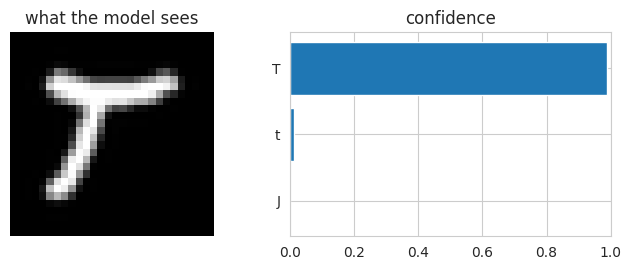

In [ ]:
# Demo without uploading anything: turn a test image into a "photo" (black ink on white paper, large) and predict it
os.makedirs("demo", exist_ok=True)
for k in range(3):
    i = int(np.random.default_rng(10 + k).integers(len(Xe_test)))
    photo = Image.fromarray((255 - Xe_test[i].squeeze() * 255).astype("uint8")).resize((280, 280), Image.BICUBIC)
    path = f"demo/sample_{k}.png"; photo.save(path)
    print("True character:", EMNIST_LABELS[ye_test[i]])
    predict_character(path)

In [ ]:
# Your own handwriting (Colab): write a character in BLACK pen on WHITE paper, take a photo, and upload it
try:
    from google.colab import files
    uploaded = files.upload()
    for fname in uploaded:
        display(Image.open(fname).convert("RGB").resize((200, 200)))
        predict_character(fname)
except ImportError:
    print("File upload works on Colab only.")

**c3. Draw with your mouse using Gradio**

In [ ]:
# !pip install -q gradio     # uncomment on Colab, then run this cell
try:
    import gradio as gr

    def predict_sketch(img):
        out = predict_character(img, show=False, top=5)
        return out if out else {}

    demo = gr.Interface(fn=predict_sketch, inputs=gr.Sketchpad(), outputs=gr.Label(num_top_classes=5),
                        title="Handwritten character recognition", live=False)
    demo.launch()
except ImportError:
    print("Install gradio first:  !pip install -q gradio")

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://051fbe1514b7434dc4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**c4. Save the model**

In [ ]:
cnn_e.save("emnist_balanced_cnn.keras")
cnn_m.save("mnist_cnn.keras")
with open("emnist_labels.json", "w") as f:
    json.dump(EMNIST_LABELS, f)
print("Saved emnist_balanced_cnn.keras, mnist_cnn.keras and emnist_labels.json")

Saved emnist_balanced_cnn.keras, mnist_cnn.keras and emnist_labels.json
